# 🔢 Notebook 04 — GLCM Feature Analysis

**Phase 5 of the project**

GLCM features were already extracted using `src/extract_features.py`
and saved to `features_glcm.csv`.

This notebook:
1. Loads the saved GLCM features
2. Explains what GLCM is visually
3. Shows feature distributions (Benign vs Malignant)
4. Verifies the feature quality

**Run each cell with Shift+Enter — takes < 1 minute**

In [1]:
import sys
sys.path.insert(0, r'D:\Projects\ML')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from skimage.feature import graycomatrix, graycoprops

from src.config import FEATURES_GLCM_CSV, METADATA_CSV, FIGURES_DIR, GLCM_PROPERTIES
from src.preprocessing import ImagePreprocessor
from src.glcm_features import GLCMExtractor
from src.utils import set_plot_style, save_figure

set_plot_style()
prep = ImagePreprocessor()
glcm_ext = GLCMExtractor()

# Load already-extracted features
glcm_df  = pd.read_csv(FEATURES_GLCM_CSV)
metadata = pd.read_csv(METADATA_CSV)
glcm_cols = [c for c in glcm_df.columns if c.startswith('glcm_')]

print('GLCM features loaded!')
print(f'  Shape          : {glcm_df.shape}')
print(f'  Feature columns: {len(glcm_cols)}')
print(f'  Feature names  : {glcm_cols}')

GLCM features loaded!
  Shape          : (7909, 25)
  Feature columns: 18
  Feature names  : ['glcm_d1_contrast', 'glcm_d1_dissimilarity', 'glcm_d1_homogeneity', 'glcm_d1_energy', 'glcm_d1_ASM', 'glcm_d1_correlation', 'glcm_d2_contrast', 'glcm_d2_dissimilarity', 'glcm_d2_homogeneity', 'glcm_d2_energy', 'glcm_d2_ASM', 'glcm_d2_correlation', 'glcm_d3_contrast', 'glcm_d3_dissimilarity', 'glcm_d3_homogeneity', 'glcm_d3_energy', 'glcm_d3_ASM', 'glcm_d3_correlation']


## 1. Understand GLCM Visually

📊  Saved figure → D:\Projects\ML\outputs\figures\04_glcm_visualization.png


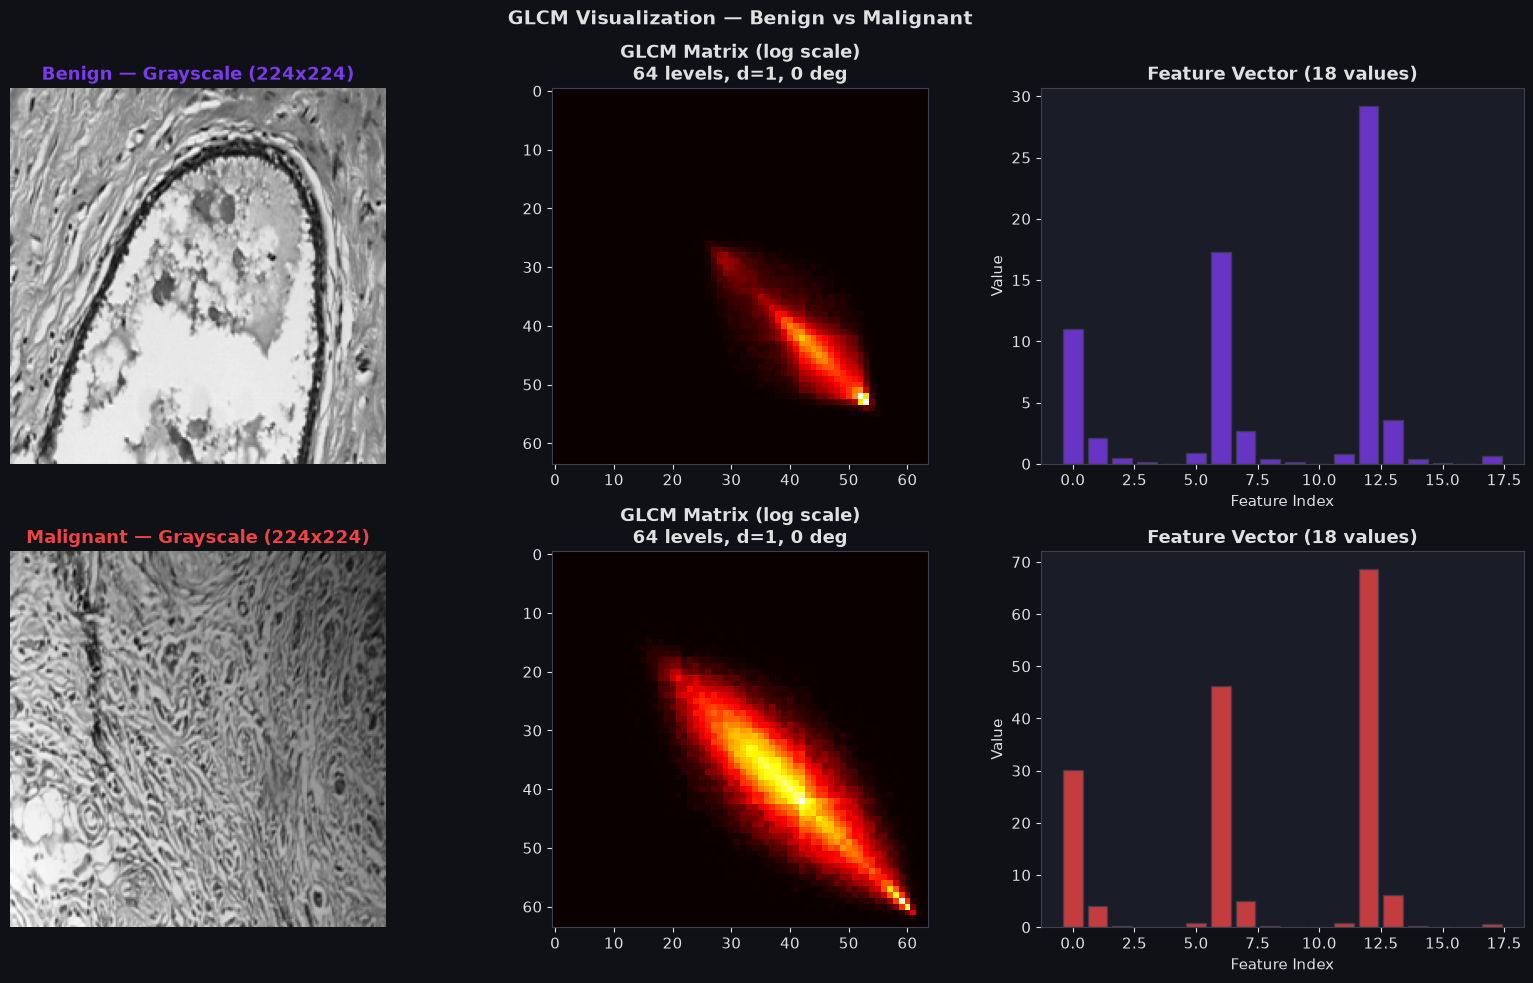

In [2]:
benign_path    = metadata[metadata['class_name']=='benign'].iloc[0]['image_path']
malignant_path = metadata[metadata['class_name']=='malignant'].iloc[0]['image_path']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('GLCM Visualization — Benign vs Malignant', fontsize=14)
PALETTE = {'Benign': '#7c3aed', 'Malignant': '#ef4444'}

for row, (path, label) in enumerate([(benign_path,'Benign'),(malignant_path,'Malignant')]):
    img = prep.preprocess_to_uint8(path)
    # Quantize to 64 levels (same as extraction script)
    img_q = (img / 255.0 * 63).astype(np.uint8)

    # Original image
    axes[row,0].imshow(img, cmap='gray')
    axes[row,0].set_title(f'{label} — Grayscale (224x224)', color=PALETTE[label])
    axes[row,0].axis('off')

    # GLCM matrix at d=1, angle=0
    g = graycomatrix(img_q, distances=[1], angles=[0], levels=64, symmetric=True, normed=True)
    axes[row,1].imshow(np.log1p(g[:,:,0,0]*1000), cmap='hot')
    axes[row,1].set_title('GLCM Matrix (log scale)\n64 levels, d=1, 0 deg')

    # Extracted feature vector
    feats = glcm_ext.extract(img_q)
    axes[row,2].bar(range(len(feats)), feats,
                    color=PALETTE[label], edgecolor='#3d3f4e', alpha=0.8)
    axes[row,2].set_title(f'Feature Vector ({len(feats)} values)')
    axes[row,2].set_xlabel('Feature Index')
    axes[row,2].set_ylabel('Value')

plt.tight_layout()
save_figure(fig, FIGURES_DIR / '04_glcm_visualization.png')
plt.show()

## 2. GLCM Feature Distributions — Benign vs Malignant

📊  Saved figure → D:\Projects\ML\outputs\figures\04_glcm_distributions.png


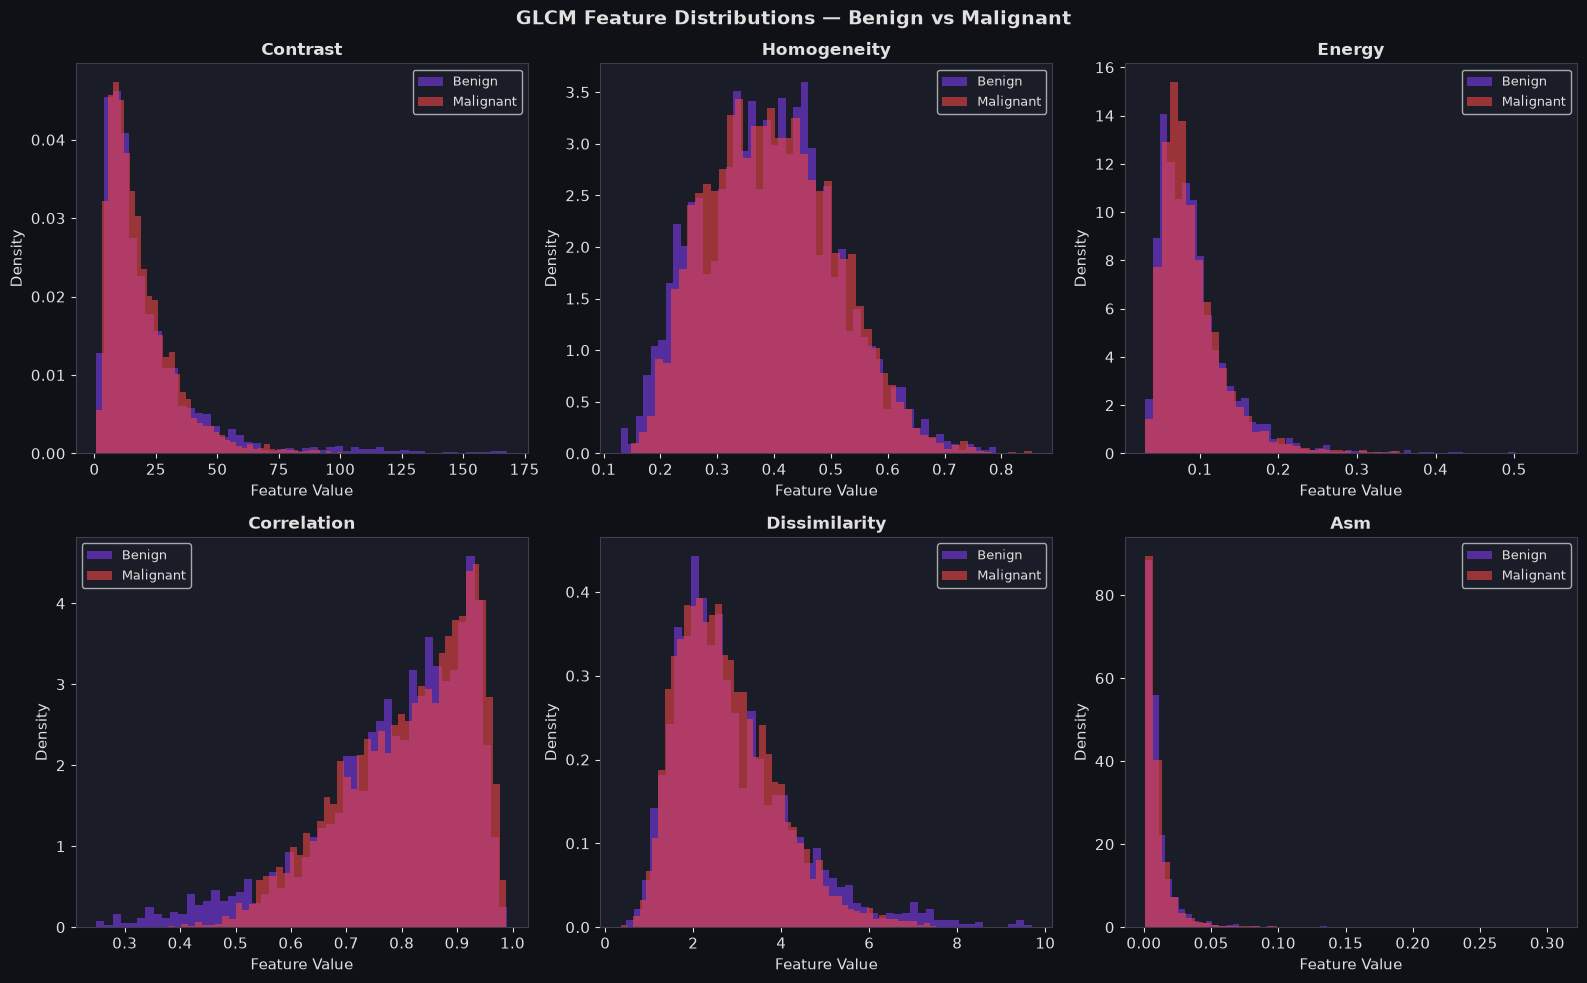

Separated distributions = discriminative features!


In [3]:
key_features = ['glcm_d1_contrast', 'glcm_d1_homogeneity',
                'glcm_d1_energy',   'glcm_d1_correlation',
                'glcm_d1_dissimilarity', 'glcm_d1_ASM']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('GLCM Feature Distributions — Benign vs Malignant', fontsize=14)
axes = axes.flatten()
HIST_PALETTE = {'benign': '#7c3aed', 'malignant': '#ef4444'}

for i, feat in enumerate(key_features):
    for cls in ['benign', 'malignant']:
        vals = glcm_df[glcm_df['class_name']==cls][feat]
        axes[i].hist(vals, bins=50, alpha=0.6,
                     color=HIST_PALETTE[cls],
                     label=cls.capitalize(), density=True)
    feat_label = feat.replace('glcm_d1_','').capitalize()
    axes[i].set_title(feat_label, fontsize=12)
    axes[i].set_xlabel('Feature Value')
    axes[i].set_ylabel('Density')
    axes[i].legend(fontsize=9)

plt.tight_layout()
save_figure(fig, FIGURES_DIR / '04_glcm_distributions.png')
plt.show()
print('Separated distributions = discriminative features!')

## 3. Feature Statistics Summary

In [4]:
print('Mean GLCM feature values per class:')
print(glcm_df.groupby('class_name')[glcm_cols].mean().T.to_string())
print()
print('='*55)
print('  PHASE 5 COMPLETE - GLCM Feature Analysis')
print('='*55)
print(f'  Total images with features: {len(glcm_df):,}')
print(f'  GLCM features per image   : {len(glcm_cols)}')
print(f'  Settings: 4 angles x 3 distances x 6 properties')
print(f'            averaged over angles = 18 features')
print(f'  Gray levels: 64 (industry standard)')
print()
print('  Next: Run Notebook 05 - Feature Fusion')
print('='*55)

Mean GLCM feature values per class:
class_name                benign  malignant
glcm_d1_contrast       21.790418  18.676316
glcm_d1_dissimilarity   2.912460   2.776053
glcm_d1_homogeneity     0.390853   0.396891
glcm_d1_energy          0.091801   0.091133
glcm_d1_ASM             0.010632   0.010232
glcm_d1_correlation     0.787706   0.810230
glcm_d2_contrast       32.007168  29.049325
glcm_d2_dissimilarity   3.634601   3.526258
glcm_d2_homogeneity     0.337729   0.342200
glcm_d2_energy          0.084402   0.083563
glcm_d2_ASM             0.009160   0.008776
glcm_d2_correlation     0.687534   0.710058
glcm_d3_contrast       48.912431  48.247784
glcm_d3_dissimilarity   4.695491   4.698067
glcm_d3_homogeneity     0.277206   0.277583
glcm_d3_energy          0.076222   0.074767
glcm_d3_ASM             0.007655   0.007209
glcm_d3_correlation     0.523968   0.536049

  PHASE 5 COMPLETE - GLCM Feature Analysis
  Total images with features: 7,909
  GLCM features per image   : 18
  Settings: 4 a